
# Pooya Valizadeh

**GitHub:** [PooyaValizadeh](https://github.com/PooyaValizadeh)  
**Kaggle:** [PooyaValizadeh](https://www.kaggle.com/PooyaValizadeh)

---

In [28]:
# Pooya Valizadeh
## www.github.com

In [29]:
import numpy as np
import matplotlib.pyplot as plt

In [30]:
def func(x1, x2):
    return x1**2 + 2 * x2**2


def func_grad(x1, x2):
    return 2 * x1, 4 * x2

In [31]:
class Optimizers:
    def __init__(self, lr_schedule):
        self.lr_schedule = lr_schedule

    def lr(self, rate, t):
        if self.lr_schedule == "constant":
            return self.constant_lr(rate)
        elif self.lr_schedule == "power":
            return self.power_lr(rate, t)

    def constant_lr(self, rate):
        return rate

    def power_lr(self, rate, t):
        c = 1
        s = 10
        return rate / (1 + t / s) ** c

    def gradient_descent(self, x1, x2, t1, t2, func_grad, rate, t):
        gr_x1, gr_x2 = func_grad(x1, x2)
        return (
            x1 - self.lr(rate, t) * gr_x1,
            x2 - self.lr(rate, t) * gr_x2,
            0,
            0,
        )

    def stochastic_gradient_descent(self, x1, x2, t1, t2, func_grad):
        gr_x1, gr_x2 = func_grad(x1, x2)
        gr_x1 += np.random.normal(0, 1)
        gr_x2 += np.random.normal(0, 1)
        return (
            x1 - self.lr_schedule * gr_x1,
            x2 - self.lr_schedule * gr_x2,
            0,
            0,
        )

    def gradient_descent_with_momentum(self, x1, x2, v1, v2, func_grad):
        alpha = 0.9
        gr_x1, gr_x2 = func_grad(x1, x2)

        v1 = alpha * v1 - self.lr_schedule * gr_x1
        v2 = alpha * v2 - self.lr_schedule * gr_x2

        return x1 + v1, x2 + v2, v1, v2

    def nesterov_gradient_descent_with_momentum(
        self, x1, x2, v1, v2, func_grad
    ):
        alpha = 0.9

        x1 += alpha * v1
        x2 += alpha * v2

        gr_x1, gr_x2 = func_grad(x1, x2)

        v1 = alpha * v1 - self.lr_schedule * gr_x1
        v2 = alpha * v2 - self.lr_schedule * gr_x2

        return x1 + v1, x2 + v2, v1, v2

    def ada_grad(self, x1, x2, r1, r2, func_grad):
        delta = 1e-7

        gr_x1, gr_x2 = func_grad(x1, x2)

        r1 += gr_x1**2
        r2 += gr_x2**2

        x1 -= self.lr_schedule / (delta + np.sqrt(r1)) * gr_x1
        x2 -= self.lr_schedule / (delta + np.sqrt(r2)) * gr_x2

        return x1, x2, r1, r2

    def rmsprop(self, x1, x2, r1, r2, func_grad):
        delta = 1e-7
        rho = 0.9

        gr_x1, gr_x2 = func_grad(x1, x2)

        r1 = r1 * rho + (1 - rho) * gr_x1**2
        r2 = r2 * rho + (1 - rho) * gr_x2**2

        x1 -= self.lr_schedule / np.sqrt(delta + r1) * gr_x1
        x2 -= self.lr_schedule / np.sqrt(delta + r2) * gr_x2

        return x1, x2, r1, r2

    def rmsprop_nesterov(self, x1, x2, v1, v2, r1, r2, func_grad):
        alpha = 0.9
        rho = 0.9
        delta = 1e-7

        # Nesterov look-ahead
        x1 += alpha * v1
        x2 += alpha * v2

        gr_x1, gr_x2 = func_grad(x1, x2)

        # RMSProp moving average
        r1 = rho * r1 + (1 - rho) * gr_x1**2
        r2 = rho * r2 + (1 - rho) * gr_x2**2

        # Momentum update with RMSProp normalization
        v1 = alpha * v1 - self.lr_schedule * gr_x1 / np.sqrt(delta + r1)
        v2 = alpha * v2 - self.lr_schedule * gr_x2 / np.sqrt(delta + r2)

        return x1 + v1, x2 + v2, v1, v2, r1, r2

    def adam(self, x1, x2, s1, s2, r1, r2, t, func_grad):
        delta, rho1, rho2 = 1e-8, 0.9, 0.999

        gr_x1, gr_x2 = func_grad(x1, x2)

        s1 = rho1 * s1 + (1 - rho1) * gr_x1
        s2 = rho1 * s2 + (1 - rho1) * gr_x2

        r1 = rho2 * r1 + (1 - rho2) * gr_x1**2
        r2 = rho2 * r2 + (1 - rho2) * gr_x2**2

        shat1 = s1 / (1 - rho1 ** (t + 1))
        shat2 = s2 / (1 - rho1 ** (t + 1))

        rhat1 = r1 / (1 - rho2 ** (t + 1))
        rhat2 = r2 / (1 - rho2 ** (t + 1))

        x1 -= self.lr_schedule * shat1 / (np.sqrt(rhat1) + delta)
        x2 -= self.lr_schedule * shat2 / (np.sqrt(rhat2) + delta)

        return x1, x2, s1, s2, r1, r2


In [32]:
def search(optimizer, func_grad, rate=None, iteration=20):
    x1, x2, t1, t2 = -5, -2, 0, 0
    x_iterations = [(x1, x2)]

    for i in range(iteration):

        if rate is not None:
            x1, x2, t1, t2 = optimizer(
                x1, x2, t1, t2, func_grad, rate, i + 1
            )
        else:
            x1, x2, t1, t2 = optimizer(
                x1, x2, t1, t2, func_grad
            )

        x_iterations.append((x1, x2))

    print("epoch {}, x1:{}, x2:{}".format(i + 1, x1, x2))
    return x_iterations

def search_adam(optimizer_adam, func_grad, iterations=20):
    x1, x2, s1, s2, r1, r2 = -5, -2, 0, 0, 0, 0
    x_iterations = [(x1, x2)]

    for t in range(iterations):
        x1, x2, s1, s2, r1, r2 = optimizer_adam(
            x1, x2, s1, s2, r1, r2, t, func_grad
        )
        x_iterations.append((x1, x2))

    print("epoch {}, x1:{}, x2:{}".format(t + 1, x1, x2))
    return x_iterations


def search_rmsprop_nesterov(optimizer, func_grad, iterations=20):
    x1, x2 = -5, -2
    v1, v2 = 0, 0
    r1, r2 = 0, 0

    x_iterations = [(x1, x2)]

    for t in range(iterations):
        x1, x2, v1, v2, r1, r2 = optimizer(
            x1, x2, v1, v2, r1, r2, func_grad
        )
        x_iterations.append((x1, x2))

    print("epoch {}, x1:{}, x2:{}".format(t + 1, x1, x2))
    return x_iterations


def search_path(func, x_iterations):
    plt.plot(*zip(*x_iterations), "-o")
    x1, x2 = np.meshgrid(
        np.arange(-5.5, 5.5, 0.1),
        np.arange(-5.5, 5.5, 0.1),
    )
    plt.contourf(x1, x2, func(x1, x2))
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

def search_momentum(optimizer, func_grad, iterations=20):
    x1, x2 = -5, -2
    v1, v2 = 0, 0

    x_iterations = [(x1, x2)]

    for i in range(iterations):
        x1, x2, v1, v2 = optimizer(
            x1, x2, v1, v2, func_grad
        )
        x_iterations.append((x1, x2))

    print("epoch {}, x1:{}, x2:{}".format(i + 1, x1, x2))
    return x_iterations

epoch 20, x1:0.0, x2:-2.0


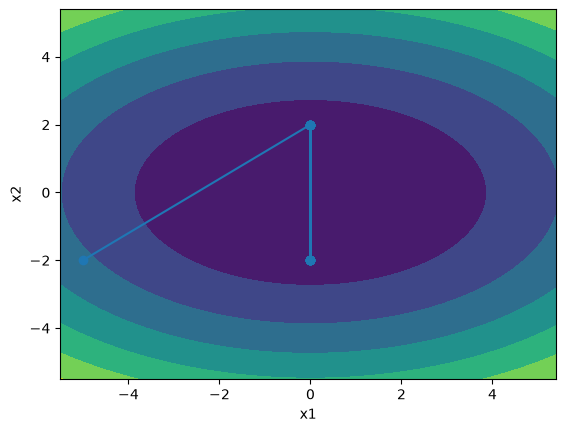

In [33]:
opt = Optimizers("constant")
search_path(func, search(opt.gradient_descent, func_grad, 0.5))


epoch 20, x1:-1.6641695802115608e-07, x2:0.0


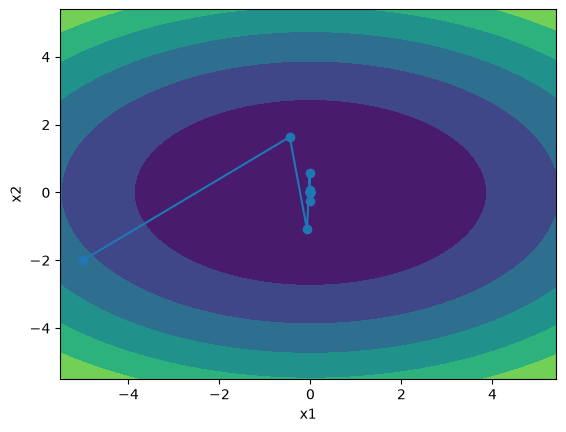

In [34]:
opt = Optimizers("power")
search_path(func, search(opt.gradient_descent, func_grad, 0.5))

epoch 20, x1:1.3779266705610334, x2:-0.5800871623873937


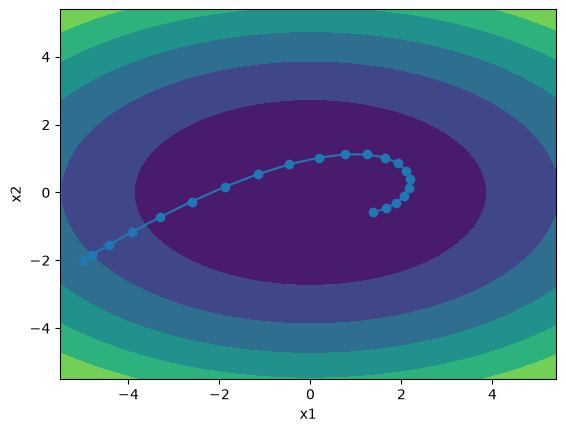

In [35]:
opt = Optimizers(0.02)
search_path(func,search_momentum(opt.gradient_descent_with_momentum,func_grad,iterations=20))

epoch 20, x1:-1.1226000420540831, x2:0.00764917525261577


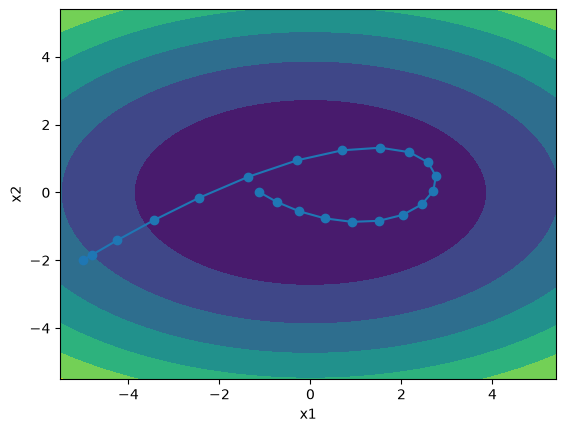

In [36]:
opt = Optimizers(0.02)
search_path(func,search_momentum(opt.nesterov_gradient_descent_with_momentum,func_grad,iterations=20))

epoch 20, x1:-1.8828800844526354, x2:-0.05646173745279083


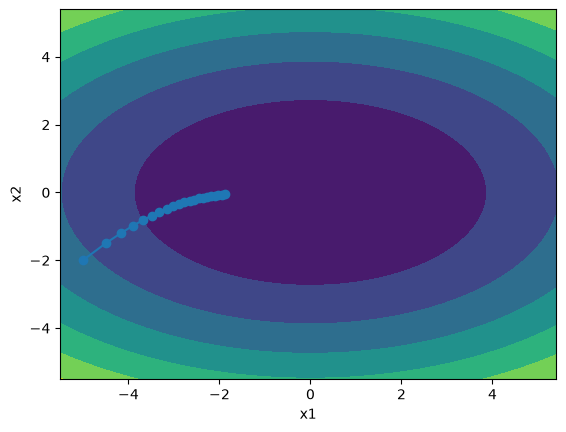

In [37]:
opt = Optimizers(0.5)
search_path(func, search(opt.ada_grad, func_grad))

epoch 20, x1:-0.000343174646715899, x2:4.843326533006444e-13


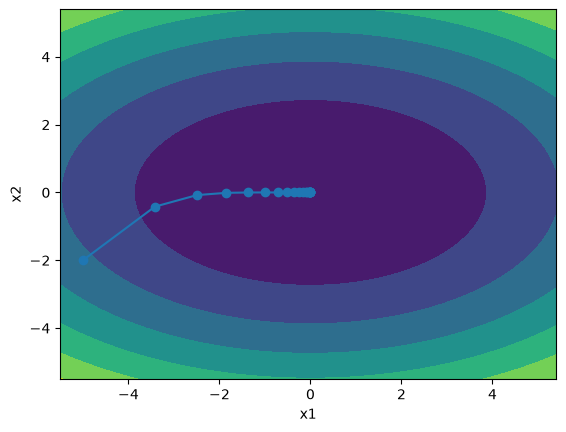

In [38]:
opt = Optimizers(0.5)
search_path(func, search(opt.rmsprop, func_grad))

epoch 20, x1:0.09247206594414789, x2:0.27886722324803453


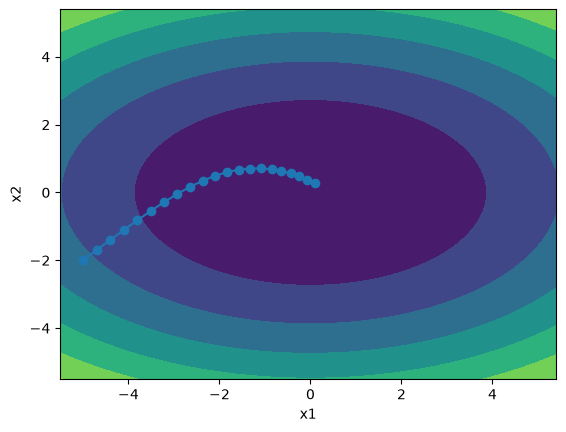

In [39]:
opt = Optimizers(0.3)
search_path(func, search_adam(opt.adam, func_grad))

epoch 20, x1:0.3971270358179866, x2:0.3869011883935403


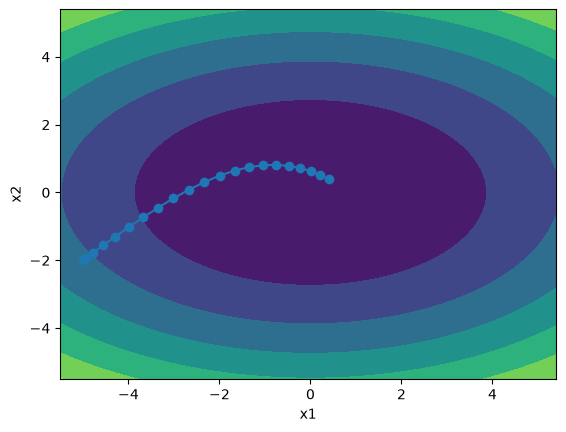

In [40]:
opt = Optimizers(0.02)
search_path(func,search_rmsprop_nesterov(opt.rmsprop_nesterov,func_grad,iterations=20,),)
